# 01 · Single-model heat-hazard screening for Australia

**CESM2 · SSP3-7.0 · daily mean temperature (`tas`) · 1970–2100**

This notebook is the project's starting point: a deliberately simple screening that uses one climate model and one emissions scenario. It asks three questions about the Australian mainland:

1. **Average warming:** how much does mean temperature rise, and where?
2. **Frequency:** how often do days that were unusually hot in 1985–2014 occur later this century?
3. **Magnitude:** how hot does a 1-in-50-year hottest day become, and how often does the 1985–2014 1-in-50-year day recur?

The last section sets out what a single-model analysis like this cannot tell you. The later notebooks in the roadmap (see the README) address those gaps one at a time.

> **A note on the variable.** `tas` is the daily *mean* near-surface air temperature. Its annual maximum is the hottest daily mean of the year, which is several degrees below the hottest daily maximum (`tasmax`).

In [1]:
import sys
from pathlib import Path

import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LogNorm

sys.path.insert(0, str(Path.cwd().parent / "src"))  # use the local package without installing it
import heatrisk as hr

DATA_DIR = Path("../data/raw")
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok=True)

# Equal 30-year windows, so every GEV fit below uses the same number of years.
BASELINE = "1985–2014"
WINDOWS = {
    "1985–2014": (1985, 2014),
    "2021–2050": (2021, 2050),
    "2041–2070": (2041, 2070),
    "2071–2100": (2071, 2100),
}
FUTURE = [name for name in WINDOWS if name != BASELINE]

# Location-level results use the nearest land grid cell (~100 km across) to each city.
CITIES = {
    "Darwin": (-12.46, 130.84),
    "Alice Springs": (-23.70, 133.88),
    "Perth": (-31.95, 115.86),
    "Melbourne": (-37.81, 144.96),
}

INK, INK_MUTED, GRID, SERIES = "#0b0b0b", "#52514e", "#e4e3df", "#2a78d6"
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.titlelocation": "left",
    "axes.edgecolor": INK_MUTED,
    "axes.labelcolor": INK,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "grid.color": GRID,
    "lines.linewidth": 1.5,
})
MAP_EXTENT = [111, 156, -39.5, -10.5]


def map_panel(ax, title):
    ax.set_extent(MAP_EXTENT, crs=ccrs.PlateCarree())
    ax.coastlines("50m", linewidth=0.6, color=INK_MUTED)
    ax.set_title(title)

## 1 · Load and tidy the data

The data are two CMIP6 runs of the NCAR CESM2 model, clipped to 100–160°E, 40–10°S:

| Run | Member | Years |
|---|---|---|
| `historical` | r1i1p1f1 | 1970–2014 |
| `ssp370` (SSP3-7.0, high emissions) | r11i1p1f1 | 2015–2100 |

`load_daily_tas` converts kelvin to °C and trims each run to its own years. The raw files overlap on 2015-01-01, and the scenario file runs one day into 2101.

**Expect a warning here.** The SSP3-7.0 run is member r11, and it continues from *historical r11*, not r1. The joined series therefore switches between two simulated climates at 2015. Averaged over 30 years, two members of the same model usually differ far less than the warming signal does, but the difference is not zero. Notebook 04 fixes this by using the matching historical member.

In [2]:
tas = hr.load_daily_tas(
    DATA_DIR / "tas_day_CESM2_historical_r1i1p1f1_gn_19700101-20141231_subset.nc",
    DATA_DIR / "tas_day_CESM2_ssp370_r11i1p1f1_gn_20150101-21001231_subset.nc",
).load()

print(f"{tas.attrs['source_id']} {tas.attrs['scenario']}: "
      f"{str(tas.time[0].values)[:10]} to {str(tas.time[-1].values)[:10]}, "
      f"{tas.sizes['time']:,} days on a {tas.sizes['lat']} × {tas.sizes['lon']} grid")
print(f"Members: historical {tas.attrs['historical_member']}, scenario {tas.attrs['scenario_member']}")

/var/folders/3l/05rqlvy551566phlkfll5nlc0000gn/T/ipykernel_77556/3216932557.py:1: UserWarning: Scenario member r11i1p1f1 branches from historical r11i1p1f1, but the historical file is r1i1p1f1: the joined series splices two different realisations at 2015-01-01.
  tas = hr.load_daily_tas(


CESM2 ssp370: 1970-01-01 to 2100-12-31, 47,815 days on a 31 × 49 grid
Members: historical r1i1p1f1, scenario r11i1p1f1


## 2 · Keep land cells and weight them by area

About 60% of the box is ocean. Ocean temperatures warm more slowly and vary much less from day to day than land temperatures do, so a plain average over every cell would understate both the warming and the extremes that matter for anything built on land. Two adjustments follow:

* **Land only.** A cell counts as land if its centre falls inside the Natural Earth coastline. At ~100 km resolution this is coarse along coasts.
* **Area weighting.** On a latitude–longitude grid, cells shrink towards the pole. At 39°S a cell covers about 20% less area than one at 11°S, so each cell is weighted by cos(latitude).

In [3]:
land = hr.land_mask(tas.lat, tas.lon)
print(f"Land cells: {int(land.sum())} of {land.size} ({float(land.mean()):.0%})")

def window(da, name):
    start, end = WINDOWS[name]
    return da.sel(time=slice(str(start), str(end)))

naive = float(window(tas, BASELINE).mean())
weighted_land = float(hr.regional_mean(window(tas, BASELINE).mean("time"), land))
print(f"{BASELINE} mean, every cell, unweighted:  {naive:5.2f} °C")
print(f"{BASELINE} mean, land only, area-weighted: {weighted_land:5.2f} °C")

Land cells: 581 of 1519 (38%)
1985–2014 mean, every cell, unweighted:  21.68 °C
1985–2014 mean, land only, area-weighted: 22.78 °C


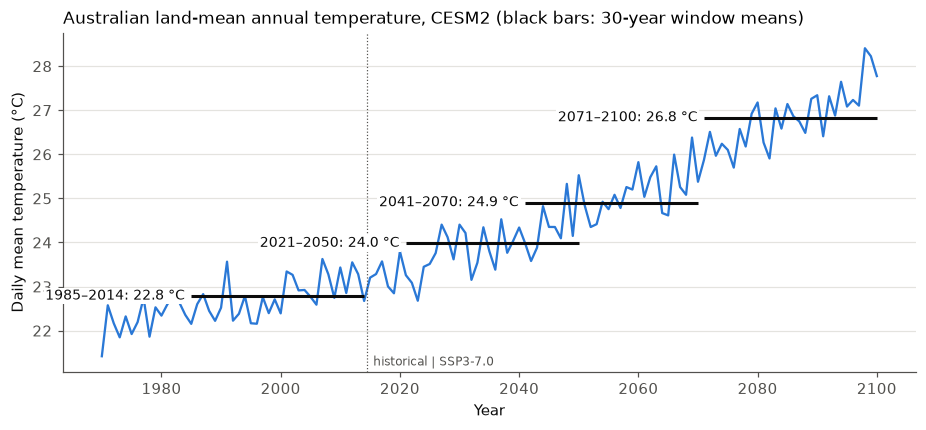

In [4]:
annual_land = hr.regional_mean(tas, land).resample(time="YS").mean()
years = annual_land.time.dt.year

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(years, annual_land, color=SERIES)
for name, (start, end) in WINDOWS.items():
    level = float(annual_land.sel(time=slice(str(start), str(end))).mean())
    ax.hlines(level, start, end, color=INK, linewidth=2)
    ax.annotate(f"{name}: {level:.1f} °C", (start, level), xytext=(-4, 0), ha="right", va="center",
                textcoords="offset points", fontsize=9, color=INK,
                bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
ax.axvline(2014.5, color=INK_MUTED, linewidth=0.8, linestyle=":")
ax.annotate("historical | SSP3-7.0", (2014.5, ax.get_ylim()[0]), xytext=(4, 4),
            textcoords="offset points", fontsize=8, color=INK_MUTED)
ax.set_title("Australian land-mean annual temperature, CESM2 (black bars: 30-year window means)")
ax.set_xlabel("Year")
ax.set_ylabel("Daily mean temperature (°C)")
ax.grid(axis="y")
fig.savefig(FIG_DIR / "01_land_mean_temperature.png")
plt.show()

## 3 · Average warming: where does it change most?

The change in each window is its mean minus the 1985–2014 mean, at every land cell. All three maps share one colour scale so that they can be compared directly.

In [5]:
window_means = {name: window(tas, name).mean("time").where(land) for name in WINDOWS}
mean_change = {name: window_means[name] - window_means[BASELINE] for name in FUTURE}

rows = []
for name, change in mean_change.items():
    rows.append({
        "Window": name,
        "Land mean ΔT (°C)": float(hr.regional_mean(change, land)),
        "Smallest cell ΔT (°C)": float(change.min()),
        "Largest cell ΔT (°C)": float(change.max()),
    })
pd.DataFrame(rows).set_index("Window").round(2)

,Land mean ΔT (°C),Smallest cell ΔT (°C),Largest cell ΔT (°C)
Window,,,
2021–2050,1.20,0.52,1.70
2041–2070,2.12,1.24,2.63
2071–2100,4.05,2.70,4.84


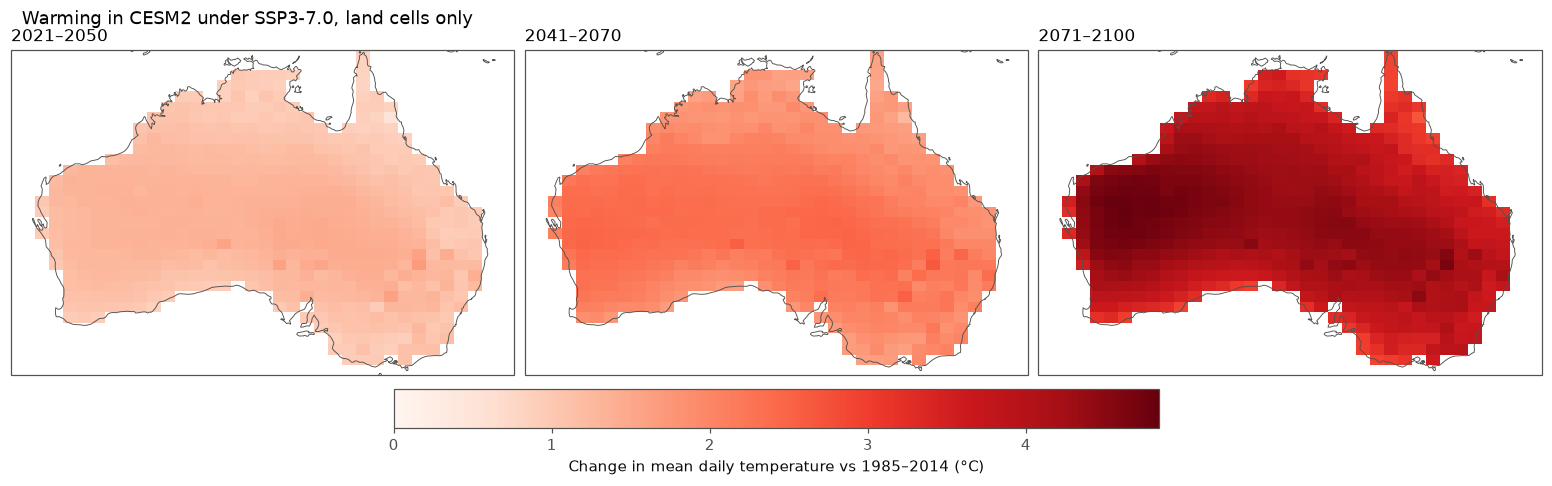

In [6]:
vmax = max(float(change.max()) for change in mean_change.values())
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), subplot_kw={"projection": ccrs.PlateCarree()},
                         layout="constrained")
for ax, (name, change) in zip(axes, mean_change.items()):
    mesh = ax.pcolormesh(tas.lon, tas.lat, change, transform=ccrs.PlateCarree(),
                         cmap="Reds", vmin=0, vmax=vmax, shading="auto")
    map_panel(ax, name)
fig.colorbar(mesh, ax=axes, orientation="horizontal", shrink=0.5, pad=0.04,
             label=f"Change in mean daily temperature vs {BASELINE} (°C)")
fig.suptitle("Warming in CESM2 under SSP3-7.0, land cells only", x=0.01, ha="left", fontsize=12)
fig.savefig(FIG_DIR / "02_mean_change_maps.png")
plt.show()

## 4 · Frequency: how often is it unusually hot?

At each cell, the threshold is the 95th percentile of all daily values in 1985–2014. That threshold then stays fixed. By construction, the baseline has about 18 days a year above it (5% of 365), so any rise afterwards shows how much more often a locally unusual temperature occurs.

**What this measure is and isn't.** It is a measure of how far the local climate shifts away from what people and infrastructure are used to. It is *not* a count of days above an engineering or health limit. Those limits are absolute temperatures that differ by asset type, and they mostly concern daily maximums, not daily means.

In [7]:
p95 = window(tas, BASELINE).quantile(0.95, dim="time").drop_vars("quantile")
hot_days = hr.annual_exceedance_days(tas, p95)
hot_days_land = hr.regional_mean(hot_days, land)

pd.DataFrame({
    "Days/year above 1985–2014 p95 (land mean)": {
        name: float(window(hot_days_land, name).mean()) for name in WINDOWS
    }
}).round(1)

,Days/year above 1985–2014 p95 (land mean)
1985–2014,18.3
2021–2050,36.5
2041–2070,52.8
2071–2100,93.7


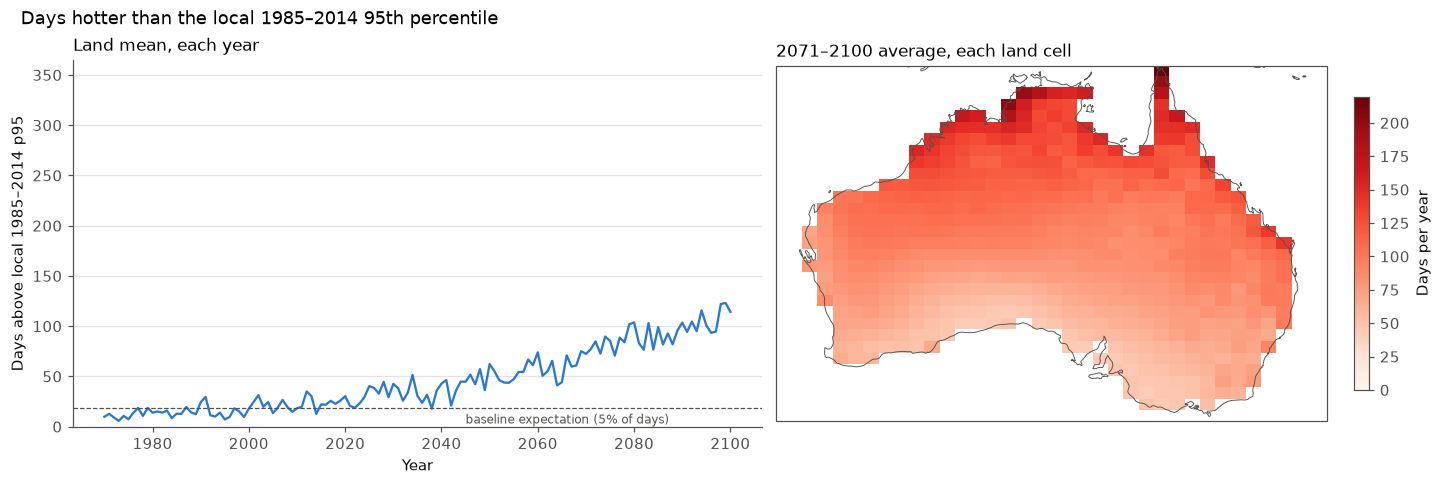

In [8]:
late_hot = window(hot_days, "2071–2100").mean("time").where(land)

fig = plt.figure(figsize=(13, 4.3), layout="constrained")
grid = fig.add_gridspec(1, 2, width_ratios=[1.25, 1])
ax_ts = fig.add_subplot(grid[0])
ax_map = fig.add_subplot(grid[1], projection=ccrs.PlateCarree())

ax_ts.plot(hot_days_land.time.dt.year, hot_days_land, color=SERIES)
ax_ts.axhline(0.05 * 365, color=INK_MUTED, linewidth=0.8, linestyle="--")
ax_ts.annotate("baseline expectation (5% of days)", (2045, 0.05 * 365), xytext=(0, -10),
               textcoords="offset points", fontsize=8, color=INK_MUTED)
ax_ts.set_title("Land mean, each year")
ax_ts.set_xlabel("Year")
ax_ts.set_ylabel("Days above local 1985–2014 p95")
ax_ts.set_ylim(0, 365)
ax_ts.grid(axis="y")

mesh = ax_map.pcolormesh(tas.lon, tas.lat, late_hot, transform=ccrs.PlateCarree(),
                         cmap="Reds", vmin=0, shading="auto")
map_panel(ax_map, "2071–2100 average, each land cell")
fig.colorbar(mesh, ax=ax_map, shrink=0.8, label="Days per year")
fig.suptitle("Days hotter than the local 1985–2014 95th percentile", x=0.01, ha="left", fontsize=12)
fig.savefig(FIG_DIR / "03_hot_day_frequency.png")
plt.show()

## 5 · Magnitude: the 1-in-50-year hottest day

At every land cell, the following steps run for each 30-year window:

1. Take the annual maximum of daily mean temperature, giving 30 values.
2. Fit a Generalised Extreme Value (GEV) distribution to those 30 values.
3. Read off two results:
   * the **50-year return level**, the temperature with a 2% chance of being exceeded in any one year;
   * the **return period of the 1985–2014 50-year level** under the future fit, i.e. how often the baseline's rare day recurs.

**Caveats worth stating up front:**
* A 50-year level estimated from 30 years is an extrapolation.
* The fit assumes the climate is steady within each window, yet it warms by roughly a degree within the late-century window.
* scipy's GEV shape parameter has the opposite sign to the usual convention. `heatrisk.extremes` notes this.

In [9]:
annual_max = hr.annual_maximum(tas.where(land))
gev = {name: hr.gev_parameters(window(annual_max, name)) for name in WINDOWS}
level_50 = {name: hr.return_level_field(params, 50) for name, params in gev.items()}
recurrence = {name: hr.return_period_field(gev[name], level_50[BASELINE]) for name in FUTURE}

pd.DataFrame({
    "50-yr level, land mean (°C)": {name: float(hr.regional_mean(level, land)) for name, level in level_50.items()},
    "Return period of 1985–2014 50-yr level, land median (years)": {
        BASELINE: 50.0, **{name: float(rp.median()) for name, rp in recurrence.items()}
    },
}).round(1)

,"50-yr level, land mean (°C)","Return period of 1985–2014 50-yr level, land median (years)"
1985–2014,38.0,50.0
2021–2050,39.7,4.0
2041–2070,40.7,2.0
2071–2100,42.7,1.1


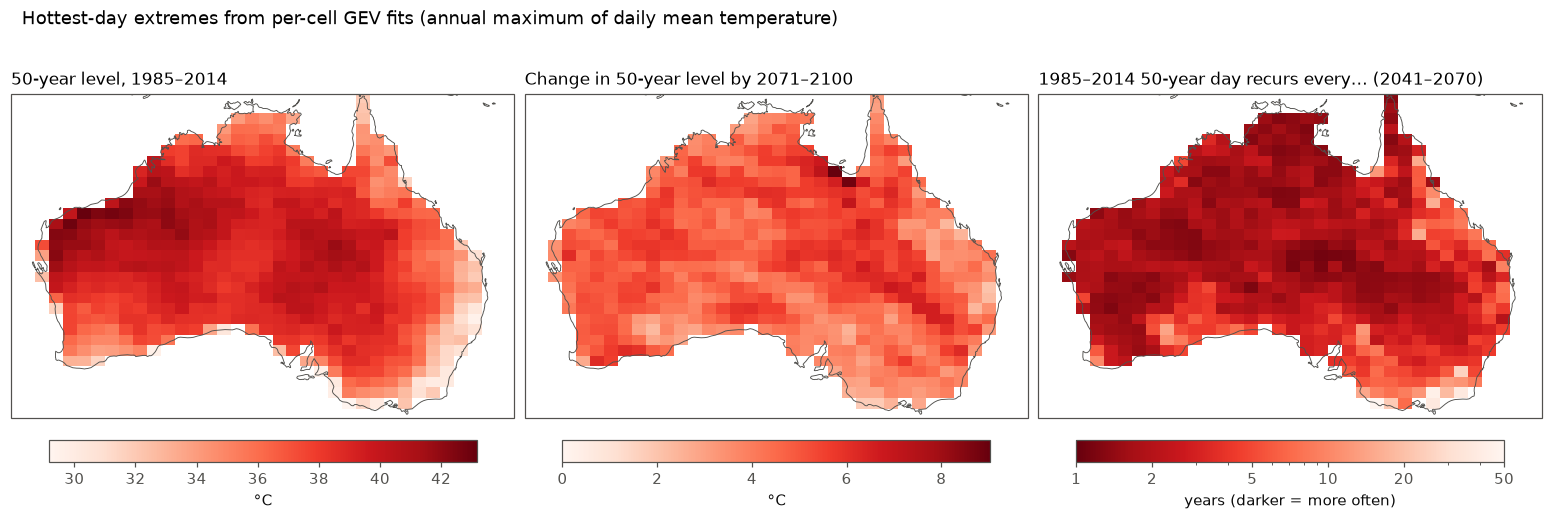

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6), subplot_kw={"projection": ccrs.PlateCarree()},
                         layout="constrained")

mesh = axes[0].pcolormesh(tas.lon, tas.lat, level_50[BASELINE], transform=ccrs.PlateCarree(),
                          cmap="Reds", shading="auto")
map_panel(axes[0], f"50-year level, {BASELINE}")
fig.colorbar(mesh, ax=axes[0], orientation="horizontal", shrink=0.85, label="°C")

change_50 = level_50["2071–2100"] - level_50[BASELINE]
mesh = axes[1].pcolormesh(tas.lon, tas.lat, change_50, transform=ccrs.PlateCarree(),
                          cmap="Reds", vmin=0, shading="auto")
map_panel(axes[1], "Change in 50-year level by 2071–2100")
fig.colorbar(mesh, ax=axes[1], orientation="horizontal", shrink=0.85, label="°C")

mesh = axes[2].pcolormesh(tas.lon, tas.lat, recurrence["2041–2070"].clip(1, 50),
                          transform=ccrs.PlateCarree(), cmap="Reds_r",
                          norm=LogNorm(vmin=1, vmax=50), shading="auto")
map_panel(axes[2], f"{BASELINE} 50-year day recurs every… (2041–2070)")
bar = fig.colorbar(mesh, ax=axes[2], orientation="horizontal", shrink=0.85, label="years (darker = more often)")
bar.set_ticks([1, 2, 5, 10, 20, 50], labels=["1", "2", "5", "10", "20", "50"])

fig.suptitle("Hottest-day extremes from per-cell GEV fits (annual maximum of daily mean temperature)",
             x=0.01, ha="left", fontsize=12)
fig.savefig(FIG_DIR / "04_extremes_maps.png")
plt.show()

## 6 · Reference cities, with sampling uncertainty

A single best-estimate return level hides how uncertain it is. For the grid cell nearest each reference city, the 50-year level is re-estimated from 1,000 bootstrap resamples of the 30 annual maximums, giving a 90% interval.

This interval reflects **sampling uncertainty only**. It says nothing about how different models, scenarios or members would change the answer, and those differences are usually larger.

In [11]:
city_rows = []
for city, (lat, lon) in CITIES.items():
    cell_lat, cell_lon = hr.nearest_land_cell(land, lat, lon)
    series = annual_max.sel(lat=cell_lat, lon=cell_lon)
    for name in WINDOWS:
        best, lower, upper = hr.bootstrap_return_level(window(series, name).values, 50, n_boot=1000)
        city_rows.append({"City": city, "Cell": f"{cell_lat:.1f}°, {cell_lon:.1f}°", "Window": name,
                          "50-yr level (°C)": best, "90% low": lower, "90% high": upper})
cities = pd.DataFrame(city_rows)
cities.pivot(index="City", columns="Window", values="50-yr level (°C)").loc[list(CITIES)].round(1)

Window,1985–2014,2021–2050,2041–2070,2071–2100
City,,,,
Darwin,34.0,35.5,35.8,36.9
Alice Springs,38.7,40.1,41.4,44.0
Perth,37.6,42.0,40.6,42.4
Melbourne,33.9,36.0,35.5,37.5


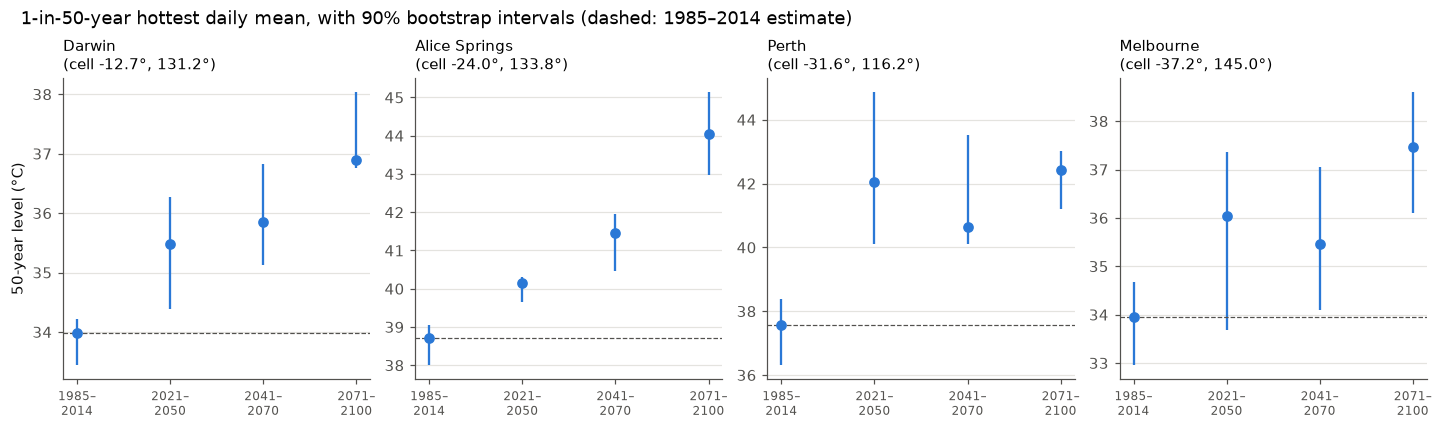

In [12]:
fig, axes = plt.subplots(1, len(CITIES), figsize=(13, 3.8), sharex=True, layout="constrained")
x = np.arange(len(WINDOWS))
for ax, city in zip(axes, CITIES):
    rows = cities[cities.City == city]
    ax.errorbar(x, rows["50-yr level (°C)"],
                yerr=[rows["50-yr level (°C)"] - rows["90% low"], rows["90% high"] - rows["50-yr level (°C)"]],
                fmt="o", markersize=6, color=SERIES, ecolor=SERIES, elinewidth=1.5, capsize=0)
    ax.axhline(rows["50-yr level (°C)"].iloc[0], color=INK_MUTED, linewidth=0.8, linestyle="--")
    ax.set_title(f"{city}\n(cell {rows.Cell.iloc[0]})", fontsize=10)
    ax.set_xticks(x, [name.replace("–", "–\n") for name in WINDOWS], fontsize=8)
    ax.grid(axis="y")
axes[0].set_ylabel("50-year level (°C)")
fig.suptitle("1-in-50-year hottest daily mean, with 90% bootstrap intervals (dashed: 1985–2014 estimate)",
             x=0.01, ha="left", fontsize=12)
fig.savefig(FIG_DIR / "05_city_return_levels.png")
plt.show()

## 7 · What this screening shows, and what it can't

**What this one simulation shows (CESM2, SSP3-7.0, relative to 1985–2014):**

* **Average warming.** Australian land warms by about 1.2 °C in 2021–2050, 2.1 °C in 2041–2070 and 4.1 °C in 2071–2100. Warming is strongest in the western and central interior and weakest along the east and south coasts.
* **Frequency.** Days above the local 1985–2014 95th percentile rise from about 18 a year to 37, 53 and 94 a year, averaged over land. The increase is largest in the tropical north. That fits with the north's small day-to-day temperature range: a modest shift there crosses the local threshold often.
* **Magnitude.** The land-average 1-in-50-year hottest daily mean rises from 38.0 °C to 42.7 °C by 2071–2100. At the median land cell, the 1985–2014 1-in-50-year day becomes roughly a 1-in-4-year event in 2021–2050 and a 1-in-2-year event in 2041–2070. By 2071–2100 it happens almost every year.
* **Uncertainty is visible even here.** At the city cells the bootstrap intervals are wide, and Perth's estimate is higher in 2021–2050 than in 2041–2070. That is not cooling. It shows how unstable a 50-year level fitted to 30 years can be, which is why a single return level should never be reported without its interval.

**Bottom line:** in this model the direction of change is clear and large. The exact numbers depend on choices (model, scenario, member, variable, statistical method) that the later notebooks test one at a time.

### Limitations, roughly in order of importance

| Limitation | Why it matters | Planned fix |
|---|---|---|
| One model | CESM2 is one of the CMIP6 models with the highest climate sensitivity, so it likely sits near the warm end of the range | Multi-model ensemble (notebook 03, using the seven BARPA-R driving models) |
| One scenario | SSP3-7.0 is a high-emissions pathway | Add SSP1-2.6 and SSP2-4.5 |
| Spliced members | Historical r1 joined to scenario r11 | Use historical r11 (notebook 04) |
| Daily mean, not maximum | Heat stress on people and assets depends on daytime peaks, warm nights and humidity | Notebook 02 uses `tasmax` for Tasmania |
| Raw model output on a ~100 km grid | No bias correction against observations; coasts and terrain are smoothed out | Notebook 02 evaluates the BARPA-R regional model against AGCD for Tasmania |
| Stationary GEV, 30-year windows | Warming within each window widens the fitted distribution; 50-year levels are extrapolated | Fit a GEV with a time-varying location parameter |
| Hazard only | Says nothing about who or what is exposed, or how vulnerable they are | Out of scope: this is a hazard screening, not a risk assessment |
| Mainland only | The data stop at 39°S, so Tasmania is not covered | Tasmania with BARPA-R (notebook 02) |